# Train Mask2Former Swin-T (Hugging Face transformers)

Thin runner over `iiss.models.m2f.train` (same code as `python -m iiss.train --run configs/runs/m2f_s<S>_seed42.yaml`). One notebook execution = one run; change only the parameters cell to launch another S.

- Run order (priority): the S=640 baseline first, then S=320 and S=960 (`.agent/experiments.md`).
- The 2-hour cap is cumulative per run id over all sessions, including hard kills (logged as `killed`). A capped or stopped run is continued with `RESUME = True`; a fresh start refuses to overwrite an existing `weights/last.pt`.
- The evaluated checkpoint is `weights/last.pt`; `best.pt` is logged only.
- Keep the outputs of this notebook after a real run: they are process evidence.
- `SMOKE = True`: 16 train / 8 valid images, S=320, 2 epochs, 5-minute cap, written to `runs/smoke/`.
- Keep the laptop plugged in and awake; close other GPU programs.

## Parameters

In [1]:
MODEL = 'm2f'
S = 320              # 320 / 640 / 960 -> configs/runs/m2f_s<S>_seed<SEED>.yaml
SEED = 42
RESUME = False       # True: continue from weights/last.pt (after a stop, crash or cap)
RUNS_ROOT = None     # None = runs/ in the repo (override, e.g. Google Drive on Colab)
COLAB = False        # True: run the Colab setup cell below first
REPO_URL = 'https://github.com/luminolous/indoor-instance-seg-shift.git'
DRIVE_DATASET = '/content/drive/MyDrive/iiss/panoptic-indoor-segmentation.v5i.coco-segmentation'
DRIVE_RUNS = '/content/drive/MyDrive/iiss/runs'
SMOKE = False

## Colab setup (optional)

Only for runs that do not fit locally. Skipped when `COLAB = False`. Not tested by Claude Code (no Colab access): check the paths before relying on it.

Before running: upload the dataset folder `panoptic-indoor-segmentation.v5i.coco-segmentation` to `DRIVE_DATASET` on Google Drive. Runs are written to `DRIVE_RUNS` so they survive a disconnect; resume with `RESUME = True` after reconnecting. Log the Colab GPU in `logbook.md`: speed and memory differ from the laptop.

In [2]:
if COLAB:
    import os, shutil, subprocess
    from google.colab import drive

    drive.mount('/content/drive')
    if not os.path.isdir('/content/indoor-instance-seg-shift'):
        subprocess.run(['git', 'clone', REPO_URL, '/content/indoor-instance-seg-shift'], check=True)
    os.chdir('/content/indoor-instance-seg-shift')
    subprocess.run(['pip', 'install', '-q', '-e', '.'], check=True)
    dst = 'dataset/panoptic-indoor-segmentation.v5i.coco-segmentation'
    if not os.path.isdir(dst):
        shutil.copytree(DRIVE_DATASET, dst)
    RUNS_ROOT = DRIVE_RUNS

## Config

In [3]:
import importlib

import pandas as pd
import torch
from IPython.display import display

from iiss.analysis.training import (config_table, gpu_sessions, notebook_config,
                                    plot_history, run_summary)
from iiss.models.common import run_dir
from iiss.utils.log import setup_logging

setup_logging()
cfg = notebook_config(MODEL, S, SEED, smoke=SMOKE, runs_root=RUNS_ROOT)
print(torch.__version__, torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU')
config_table(cfg)

2.14.1+cu126 NVIDIA GeForce RTX 4050 Laptop GPU


,value
run_id,m2f_s320_seed42
input_size,320
time_cap_hours,2.0
run_dir,C:\Users\Syauqi Nabil\Lectures\University\Seme...
train.epochs,50
train.batch,2
train.accumulate,1
train.base_lr,0.0001
train.base_batch,2
train.weight_decay,0.05


## Status before training

In [4]:
pd.Series(run_summary(cfg)).to_frame('value')

,value
run_id,m2f_s320_seed42
run_dir,C:\Users\Syauqi Nabil\Lectures\University\Seme...
last_pt,False
best_pt,False
epochs_done,0
epochs_planned,50
sessions,0
statuses,
gpu_hours_used,0.0
cap_hours,2.0


## Train

Logs stream below. Interrupting the kernel stops the run safely (state of the last finished epoch is kept).

In [5]:
module = importlib.import_module(f'iiss.models.{MODEL}')
out = module.train(cfg, resume=RESUME)
out

2026-11-24 02:36:26 INFO    iiss.utils.env: Wrote environment snapshot to C:\Users\Syauqi Nabil\Lectures\University\Semester 5\Computer Vision\Task\Instance Segmentation\indoor-instance-seg-shift\runs\m2f_s320_seed42\env.json


2026-11-24 02:36:26 INFO    iiss.utils.seed: Seeded everything with seed=42 (deterministic=False)


C:\Users\Syauqi Nabil\Lectures\University\Semester 5\Computer Vision\Task\Instance Segmentation\indoor-instance-seg-shift\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Loading weights:   0%|          | 0/554 [00:00<?, ?it/s]

Loading weights:  22%|██▏       | 122/554 [00:00<00:00, 1096.20it/s]

Loading weights: 100%|██████████| 554/554 [00:00<00:00, 4349.16it/s]

... (1,744 outputs left out)

2026-11-24 03:21:33 INFO    iiss.eval.results_json: Wrote 16321 results to C:\Users\Syauqi Nabil\Lectures\University\Semester 5\Computer Vision\Task\Instance Segmentation\indoor-instance-seg-shift\runs\m2f_s320_seed42\val\last.json


2026-11-24 03:21:36 INFO    iiss.models.torch_loop: Epoch 50/50: loss 9.9372, valid mask AP 0.25723, 77 s


2026-11-24 03:21:36 INFO    iiss.utils.timer: Timer stopped for m2f_s320_seed42: 2683.4 s this session, status=completed, peak VRAM 2150.0 MB


WindowsPath('C:/Users/Syauqi Nabil/Lectures/University/Semester 5/Computer Vision/Task/Instance Segmentation/indoor-instance-seg-shift/runs/m2f_s320_seed42')

## Result

GPU time per session (`runs/gpu_time_log.csv`), run status and training curves (also saved as `<run_dir>/curves.png`). The validation curve of YOLO is Ultralytics' validator; the comparable numbers come from `predict_and_evaluate.ipynb`.

,run_id,start,end,wall_clock_s,gpu_name,peak_vram_mb,cap_hit,status
0,m2f_s320_seed42,2026-11-24T02:36:53+07:00,2026-11-24T03:21:36+07:00,2683.4,NVIDIA GeForce RTX 4050 Laptop GPU,2150.0,False,completed


,value
run_id,m2f_s320_seed42
run_dir,C:\Users\Syauqi Nabil\Lectures\University\Seme...
last_pt,True
best_pt,True
epochs_done,50
epochs_planned,50
sessions,1
statuses,completed
gpu_hours_used,0.745
cap_hours,2.0


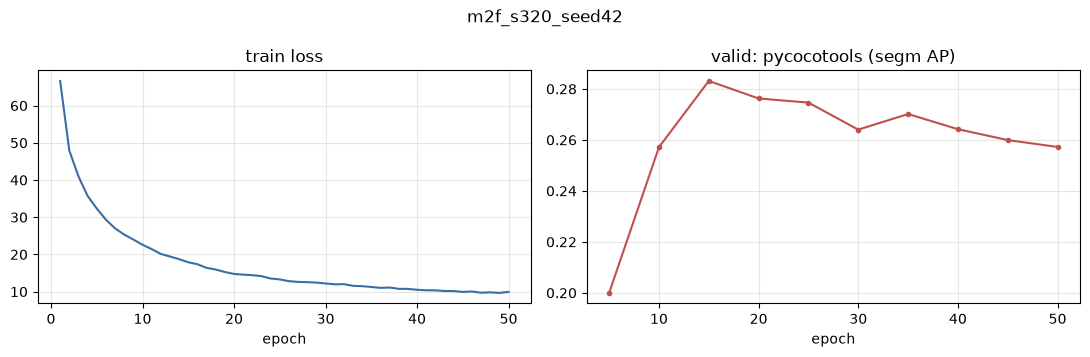

In [6]:
display(gpu_sessions(cfg))
display(pd.Series(run_summary(cfg)).to_frame('value'))
fig = plot_history(cfg, save_to=run_dir(cfg) / 'curves.png')

## Next step

Send back the summary table above (run id, epochs, GPU hours, last/best valid metric). Then run the next S, or `predict_and_evaluate.ipynb`.